# Graph Neural Networks: The Basics

Welcome to the first notebook of the **SheafMPNN** tutorial series. Before we attach vector spaces and restriction maps to graphs (notebook 1 onwards), we need a clear picture of what a *standard* Graph Neural Network (GNN) computes, why it works, and where it breaks down.

This notebook builds that picture from the ground up. As in the rest of the series, every concept is introduced with its equations, then implemented in a small, fully executable experiment that you can modify.

### What You Will Learn
* How a graph is stored as tensors: adjacency, degree, Laplacian, and PyTorch Geometric's `edge_index`.
* The **message passing** template that unifies almost every GNN, and why it must be permutation equivariant.
* The **spectral** view: graph frequencies, smoothness, and why a GCN layer is a low-pass filter.
* Four landmark architectures, namely **GCN**, **GraphSAGE**, **GAT**, and **GIN**: their equations, a from-scratch check against PyTorch Geometric, training, and comparison.
* How to **interpret** a GNN through attention weights, gradient-based edge importance, and embedding geometry.
* The main **failure modes** (oversmoothing, heterophily, oversquashing, limited expressivity) and how they motivate sheaf neural networks.

### Notebook Roadmap
1. **Represent** graphs as tensors and inspect a real network.
2. **Formalize** message passing and verify its symmetry properties.
3. **Analyze** graph signals spectrally and derive the GCN layer.
4. **Implement and compare** GCN, GraphSAGE, GAT, and GIN.
5. **Interpret** what the trained models rely on.
6. **Diagnose** classical GNN limitations, then bridge to sheaves.

No dataset download is needed: everything runs on Zachary's Karate Club (bundled with PyTorch Geometric) and small synthetic graphs.

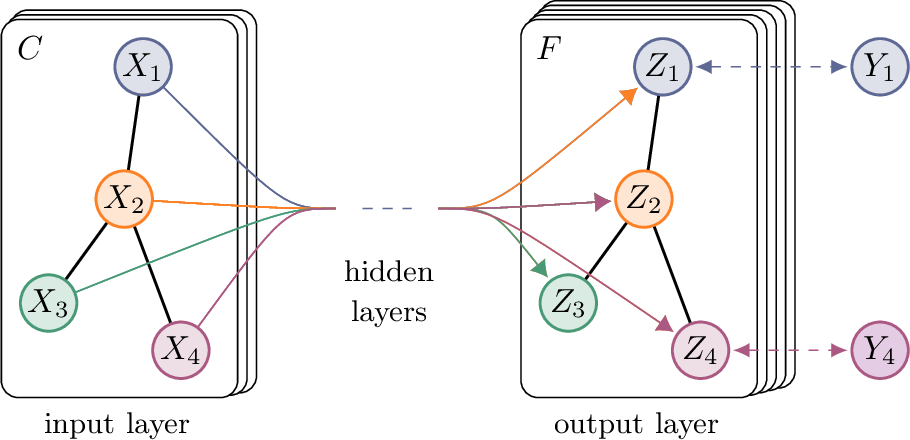

*A multi-layer GCN for semi-supervised node classification: C input channels per node are transformed by hidden graph-convolution layers into F output channels. The loss is computed only on the labelled nodes (here Y1 and Y4), but every layer mixes information along the edges, so all nodes are shaped by those labels.*

<sub>Source: Kipf & Welling (2017), *Semi-Supervised Classification with Graph Convolutional Networks*, [arXiv:1609.02907](https://arxiv.org/abs/1609.02907), Fig. 1 (left). Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Graphs as Tensors](#3-graphs-as-tensors)
    * [Adjacency, Degree, and Laplacian](#adjacency-degree-laplacian)
    * [Loading and Inspecting a Graph](#loading-a-graph)
    * [Visualizing the Graph](#visualizing-the-graph)
4. [Message Passing Neural Networks](#4-message-passing)
    * [The Message Passing Template](#mpnn-template)
    * [A Message Passing Layer from Scratch](#mpnn-from-scratch)
    * [Permutation Equivariance](#permutation-equivariance)
    * [Receptive Fields](#receptive-fields)
5. [The Spectral View](#5-spectral-view)
    * [Graph Frequencies and Dirichlet Energy](#graph-frequencies)
    * [From Spectral Filters to GCN](#spectral-to-gcn)
6. [Graph Convolutional Networks (GCN)](#6-gcn)
7. [GraphSAGE](#7-graphsage)
8. [Graph Attention Networks (GAT)](#8-gat)
9. [Graph Isomorphism Networks (GIN) and Expressive Power](#9-gin)
10. [Training and Comparing the Four Models](#10-training)
11. [Interpreting GNNs](#11-interpretability)
    * [Attention Maps](#attention-maps)
    * [Gradient-Based Edge Importance](#edge-importance)
12. [Limitations of Classical GNNs](#12-limitations)
    * [Oversmoothing](#oversmoothing)
    * [Heterophily](#heterophily)
    * [Oversquashing](#oversquashing)
    * [From GNNs to Sheaves](#gnns-to-sheaves)
13. [Summary and Exercises](#13-summary)

<a id="1-introduction"></a>
# 1. Introduction

Many datasets are naturally **relational**: users who follow each other, papers that cite each other, atoms bonded in a molecule, roads joining intersections. A graph $\mathcal{G} = (\mathcal{V}, \mathcal{E})$ stores the entities as **nodes** $u \in \mathcal{V}$ and the relations as **edges** $(u, v) \in \mathcal{E}$, with a feature vector $\mathbf{x}_u \in \mathbb{R}^{f}$ attached to every node.

GNNs learn from this structure at three levels:
* **Node level:** predict a property of each node (the topic of a paper, the role of a user). This is the setting of most notebooks in this series.
* **Edge level:** predict whether, or how, two nodes are related (link prediction, recommendation).
* **Graph level:** predict a property of a whole graph (the toxicity of a molecule).

Three inductive biases make GNNs work, by analogy with convolutional networks on images:
1. **Locality.** A node is updated from its neighbours, so one layer sees one hop and $L$ layers see $L$ hops.
2. **Weight sharing.** The same parameters process every node and every edge, so the parameter count does not grow with the graph.
3. **Permutation symmetry.** Node indices are arbitrary labels. Relabelling the nodes must relabel the outputs in the same way (*equivariance*) and leave graph-level predictions unchanged (*invariance*).

A fourth, often implicit, assumption is **homophily**: connected nodes tend to be similar. Most classical GNNs average over neighbours, which helps when neighbours agree and hurts when they do not. That tension is the starting point for sheaf neural networks.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

This notebook needs only PyTorch, PyTorch Geometric, NetworkX (installed with PyTorch), Matplotlib, and scikit-learn. It does not import the repository's sheaf models, but it uses the same repository-root detection as the other notebooks so that the series shares one setup.

Use the repository's Python 3.13 environment (`uv sync`) and run the cells top to bottom from a fresh kernel.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# =====================================================================
# 2. Core Scientific Libraries
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data

# =====================================================================
# 3. Reproducibility
# =====================================================================
warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)  # noqa: NPY002
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # small graphs: avoid thread overhead and nondeterminism

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

# =====================================================================
# 4. Graph Learning Libraries
# =====================================================================
import networkx as nx
from sklearn.decomposition import PCA
from torch_geometric.datasets import KarateClub
from torch_geometric.nn import GATConv, GCNConv, GINConv, MessagePassing, SAGEConv
from torch_geometric.utils import (
    homophily,
    stochastic_blockmodel_graph,
    to_dense_adj,
    to_networkx,
    to_undirected,
)

print("PyG layers loaded: GCNConv, SAGEConv, GATConv, GINConv")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0


PyG layers loaded: GCNConv, SAGEConv, GATConv, GINConv


<a id="3-graphs-as-tensors"></a>
# 3. Graphs as Tensors

<a id="adjacency-degree-laplacian"></a>
### 3.1 Adjacency, Degree, and Laplacian

For a graph with $n$ nodes, the **adjacency matrix** $A \in \{0, 1\}^{n \times n}$ has $A_{uv} = 1$ when $u$ and $v$ are connected. For an undirected graph, $A$ is symmetric. The **degree** of a node is its number of neighbours, $d_u = \sum_v A_{uv}$, collected in the diagonal matrix $D = \operatorname{diag}(d_1, \dots, d_n)$.

Two matrices built from them appear everywhere:
* The **graph Laplacian** $L = D - A$, which acts on a signal $\mathbf{x}$ as $(L\mathbf{x})_u = \sum_{v \in \mathcal{N}(u)} (\mathbf{x}_u - \mathbf{x}_v)$. It measures how much a node *disagrees* with its neighbours.
* The **symmetrically normalized Laplacian** $\Delta = I - D^{-1/2} A D^{-1/2}$, whose eigenvalues always lie in $[0, 2]$.

Dense matrices cost $\mathcal{O}(n^2)$ memory, but real graphs are sparse. PyTorch Geometric therefore stores edges in **COO format**: an `edge_index` tensor of shape $[2, |\mathcal{E}|]$ whose columns are (source, target) pairs. An undirected edge is stored twice, once in each direction. Node features live in a matrix $X \in \mathbb{R}^{n \times f}$, stored as `data.x`.

<a id="loading-a-graph"></a>
### 3.2 Loading and Inspecting a Graph

We use **Zachary's Karate Club**, a social network of 34 club members recorded just before the club split in two. PyTorch Geometric ships it with 4 community labels obtained by modularity clustering, and with exactly **one labelled node per community** for training. This is the same semi-supervised setup used in the original GCN paper.

The node features are one-hot identity vectors, so the model knows *which* node it is looking at but nothing else. Any useful signal must therefore come from the graph structure.

In [2]:
# =====================================================================
# Load Zachary's Karate Club (bundled with PyG: no download)
# =====================================================================
dataset = KarateClub()
data = dataset[0]
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
data.test_mask = ~data.train_mask  # every unlabelled node is a test node

num_nodes = data.x.size(0)
num_classes = int(data.y.max()) + 1

print("--- 1. Metadata ---")
print(f"PyG Data object:  {data}")
print(f"Nodes:            {num_nodes}")
print(f"Stored edges:     {data.num_edges}  (each undirected edge stored twice)")
print(f"Node features:    {data.num_node_features}  (one-hot identity)")
print(f"Classes:          {num_classes}")
print(f"Training nodes:   {data.train_mask.nonzero().flatten().tolist()}")

# =====================================================================
# Dense views of the same graph
# =====================================================================
A = to_dense_adj(data.edge_index, max_num_nodes=num_nodes)[0]
deg = A.sum(1)
L = torch.diag(deg) - A
D_inv_sqrt = deg.pow(-0.5)
Delta = torch.eye(num_nodes) - D_inv_sqrt[:, None] * A * D_inv_sqrt[None, :]

print("\n--- 2. Matrix Views ---")
print(f"Adjacency symmetric:        {torch.equal(A, A.T)}")
print(f"Degree range:               {int(deg.min())} .. {int(deg.max())}")
print(f"Laplacian rows sum to zero: {torch.allclose(L.sum(1), torch.zeros(num_nodes))}")
eig_delta = torch.linalg.eigvalsh(Delta)
print(
    f"Normalized spectrum range:  [{eig_delta.min():.3f}, {eig_delta.max():.3f}]  (always inside [0, 2])"
)

# =====================================================================
# Homophily: how often do connected nodes share a label?
# =====================================================================
h_edge = homophily(data.edge_index, data.y, method="edge")
print("\n--- 3. Homophily ---")
print(f"Edge homophily: {h_edge:.3f}  (fraction of edges joining same-label nodes)")
print(f"Random baseline for {num_classes} balanced classes: {1 / num_classes:.3f}")

--- 1. Metadata ---
PyG Data object:  Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34], test_mask=[34])
Nodes:            34
Stored edges:     156  (each undirected edge stored twice)
Node features:    34  (one-hot identity)
Classes:          4
Training nodes:   [0, 4, 8, 24]

--- 2. Matrix Views ---
Adjacency symmetric:        True
Degree range:               1 .. 17
Laplacian rows sum to zero: True
Normalized spectrum range:  [0.000, 1.715]  (always inside [0, 2])

--- 3. Homophily ---
Edge homophily: 0.756  (fraction of edges joining same-label nodes)
Random baseline for 4 balanced classes: 0.250


An edge homophily well above the random baseline tells us this graph is **homophilic**: neighbours usually share a community. Keep this number in mind, because Section 12 shows what happens when it is low.

<a id="visualizing-the-graph"></a>
### 3.3 Visualizing the Graph

We convert the PyG object to NetworkX for drawing. Colours are the community labels; the four thick-outlined nodes are the only labels the models will ever see during training.

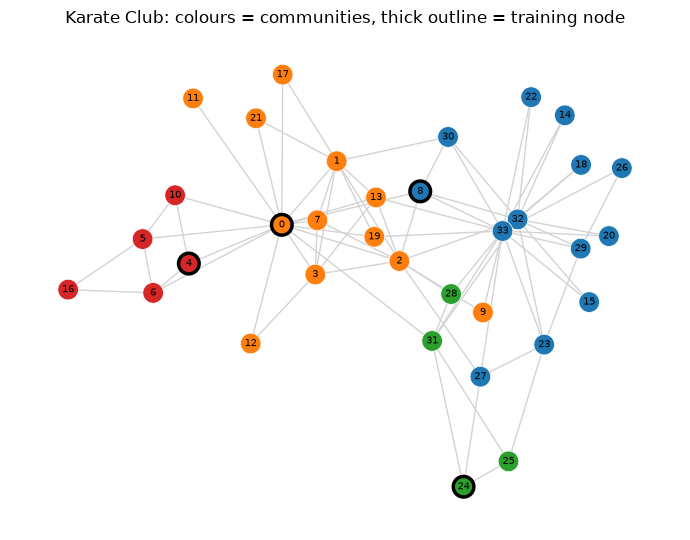

In [3]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Draw the Karate Club graph (layout reused throughout the notebook)
# =====================================================================
G = to_networkx(data, to_undirected=True)
pos = nx.spring_layout(G, seed=7)
CMAP = plt.get_cmap("tab10")
node_colors = [CMAP(int(c)) for c in data.y]


def draw_karate(ax, title, edge_width=1.0, edge_color="lightgray", highlight=None):
    """Draws the Karate graph with community colours and training-node outlines."""
    nx.draw_networkx_edges(G, pos, ax=ax, width=edge_width, edge_color=edge_color)
    assert isinstance(data, Data)
    train = data.train_mask.numpy()
    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_color=node_colors,
        node_size=220,
        edgecolors=["black" if t else "white" for t in train],
        linewidths=[2.5 if t else 0.5 for t in train],
    )
    if highlight is not None:
        nx.draw_networkx_nodes(
            G,
            pos,
            nodelist=[highlight],
            ax=ax,
            node_size=520,
            node_color="none",
            edgecolors="red",
            linewidths=2.5,
        )
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(7, 5.5))
draw_karate(ax, "Karate Club: colours = communities, thick outline = training node")
plt.tight_layout()
plt.show()

<a id="4-message-passing"></a>
# 4. Message Passing Neural Networks

<a id="mpnn-template"></a>
### 4.1 The Message Passing Template

Gilmer et al. (2017) observed that most GNNs fit one template, the **Message Passing Neural Network (MPNN)**. At layer $t$, every node $u$ with state $\mathbf{h}_u^{(t)}$ performs three steps:

1. **Message.** Each neighbour $v$ sends $\mathbf{m}_{u \leftarrow v} = \psi\big(\mathbf{h}_u^{(t)}, \mathbf{h}_v^{(t)}, \mathbf{e}_{uv}\big)$, where $\mathbf{e}_{uv}$ are optional edge features.
2. **Aggregate.** The messages are combined with a **permutation-invariant** operator such as sum, mean, or max: $\mathbf{a}_u = \bigoplus_{v \in \mathcal{N}(u)} \mathbf{m}_{u \leftarrow v}$.
3. **Update.** The node combines its own state with the aggregate: $\mathbf{h}_u^{(t+1)} = \phi\big(\mathbf{h}_u^{(t)}, \mathbf{a}_u\big)$.

$\psi$ and $\phi$ are small neural networks shared by all nodes. Because the aggregator does not care about the order of the neighbours, the whole layer is **permutation equivariant**. GCN, GraphSAGE, GAT, and GIN differ only in their choice of $\psi$, $\bigoplus$, and $\phi$.

The sheaf models of this repository fit the same template: their message is $\mathbf{m}_{u \leftarrow v} = \mathcal{F}_{u \trianglelefteq e}^{\top}(\mathcal{F}_{u \trianglelefteq e}\mathbf{h}_u - \mathcal{F}_{v \trianglelefteq e}\mathbf{h}_v)$, a comparison made *after* transporting both states into a shared edge space. This is why the repository calls them *Sheaf Message Passing Neural Networks*.

<a id="mpnn-from-scratch"></a>
### 4.2 A Message Passing Layer from Scratch

PyTorch Geometric's `MessagePassing` base class implements the gather/scatter machinery: you write `message()` and choose the aggregator, and `propagate()` does the rest. Below, we implement a minimal **mean-aggregation** layer and check it against the equivalent dense formula $H' = H W_{\text{self}}^\top + D^{-1} A H W_{\text{nbr}}^\top$.

In [4]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# A minimal MPNN layer: mean of neighbour states + own state
# =====================================================================
class MeanMessagePassing(MessagePassing):
    """h_u' = W_self h_u + W_nbr * mean_{v in N(u)} h_v"""

    def __init__(self, in_dim: int, out_dim: int):
        super().__init__(aggr="mean")  # permutation-invariant aggregator
        self.lin_self = nn.Linear(in_dim, out_dim, bias=False)
        self.lin_nbr = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, x, edge_index):
        aggregated = self.propagate(edge_index, x=x)  # ty: ignore[missing-argument]  # PyG generates propagate dynamically.
        return self.lin_self(x) + self.lin_nbr(aggregated)

    def message(self, x_j):
        # x_j holds the *source* node state for every edge (gathered by PyG).
        return x_j


set_seed(SEED)
layer = MeanMessagePassing(data.num_node_features, 8)
with torch.no_grad():
    out_mp = layer(data.x, data.edge_index)
    # Dense equivalent: row-normalized adjacency D^{-1} A averages the neighbours.
    out_dense = layer.lin_self(data.x) + layer.lin_nbr((A / deg[:, None]) @ data.x)

print("--- Message passing vs dense formula ---")
print(f"Output shape: {tuple(out_mp.shape)}")
print(f"Max abs difference: {(out_mp - out_dense).abs().max():.2e}")
assert torch.allclose(out_mp, out_dense, atol=1e-6)
print("The sparse message-passing layer equals its dense matrix formulation.")

--- Message passing vs dense formula ---
Output shape: (34, 8)
Max abs difference: 0.00e+00
The sparse message-passing layer equals its dense matrix formulation.


<a id="permutation-equivariance"></a>
### 4.3 Permutation Equivariance

Let $P$ be a permutation matrix that relabels the nodes. A node-level layer $f$ is **equivariant** if $f(PX, PAP^\top) = P\,f(X, A)$: relabelling the input relabels the output identically and changes nothing else. We verify this numerically by shuffling the node order of the Karate graph.

In [5]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Numerical check of permutation equivariance
# =====================================================================
perm = torch.randperm(num_nodes)  # new position -> old node id
inv_perm = torch.empty_like(perm)
inv_perm[perm] = torch.arange(num_nodes)  # old node id -> new position

x_perm = data.x[perm]  # P X
edge_index_perm = inv_perm[data.edge_index]  # relabel both endpoints of every edge

with torch.no_grad():
    out_original = layer(data.x, data.edge_index)
    out_permuted = layer(x_perm, edge_index_perm)

print("--- Equivariance check ---")
print(
    f"f(PX, PAP^T) == P f(X, A): {torch.allclose(out_permuted, out_original[perm], atol=1e-6)}"
)

--- Equivariance check ---
f(PX, PAP^T) == P f(X, A): True


<a id="receptive-fields"></a>
### 4.4 Receptive Fields

After $L$ layers, a node's representation can depend only on nodes within $L$ hops. The number of such nodes grows quickly, often exponentially, with $L$. This growth is what lets deep GNNs see far, but it also forces an exponentially growing amount of information through fixed-size vectors (Section 12.3, *oversquashing*).

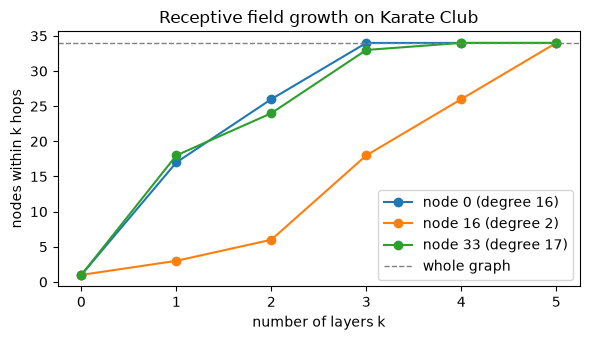

node  0: whole graph reached after 3 layers
node 16: whole graph reached after 5 layers
node 33: whole graph reached after 4 layers


In [6]:
# =====================================================================
# How many nodes can influence a node after k layers?
# =====================================================================
A_hat = (A + torch.eye(num_nodes)) > 0  # one hop, including the node itself
reach = torch.eye(num_nodes, dtype=torch.bool)
sizes = {0: [], 16: [], 33: []}
for _ in range(6):
    for node in sizes:
        sizes[node].append(int(reach[node].sum()))
    reach = (reach.float() @ A_hat.float()) > 0

fig, ax = plt.subplots(figsize=(6, 3.5))
for node, s in sizes.items():
    ax.plot(range(6), s, marker="o", label=f"node {node} (degree {int(deg[node])})")
ax.axhline(num_nodes, color="gray", ls="--", lw=1, label="whole graph")
ax.set(
    xlabel="number of layers k",
    ylabel="nodes within k hops",
    title="Receptive field growth on Karate Club",
)
ax.legend()
plt.tight_layout()
plt.show()
for node, s in sizes.items():
    print(f"node {node:>2}: whole graph reached after {s.index(num_nodes)} layers")

<a id="5-spectral-view"></a>
# 5. The Spectral View

<a id="graph-frequencies"></a>
### 5.1 Graph Frequencies and Dirichlet Energy

The Laplacian gives graphs a notion of **frequency**. Its quadratic form is the **Dirichlet energy**

$$E(\mathbf{x}) = \mathbf{x}^\top L \mathbf{x} = \tfrac{1}{2}\sum_{u}\sum_{v \in \mathcal{N}(u)} (x_u - x_v)^2,$$

which is small when the signal varies slowly across edges. Diagonalizing $\Delta = U \Lambda U^\top$ gives an orthonormal basis of eigenvectors $\mathbf{u}_k$. Each one is a "graph Fourier mode" whose (normalized) Dirichlet energy equals its eigenvalue $\lambda_k$:
* small $\lambda_k$: **low frequency**, nearly constant on densely connected regions;
* large $\lambda_k$: **high frequency**, flipping sign between neighbours.

A **spectral filter** rescales each frequency: $g(\Delta)\mathbf{x} = U\,g(\Lambda)\,U^\top\mathbf{x}$. The plot below shows four modes of the Karate graph. The second eigenvector (the *Fiedler vector*) already splits the club almost exactly along its real-world fracture.

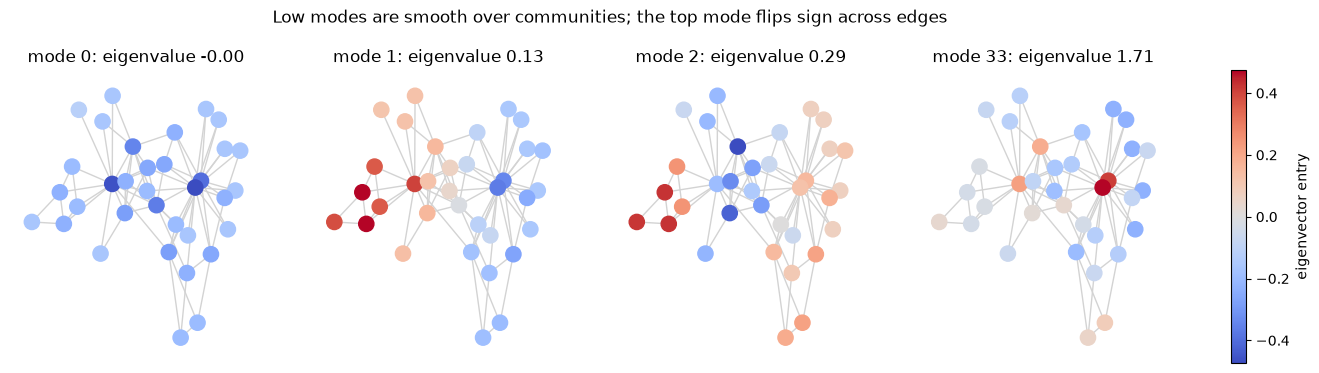

Sign of the Fiedler vector matches the real post-split factions for 94% of members.


In [7]:
# =====================================================================
# Eigenvectors of the normalized Laplacian = graph Fourier modes
# =====================================================================
evals, evecs = torch.linalg.eigh(Delta)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, k in zip(axes, [0, 1, 2, num_nodes - 1], strict=True):
    vec = evecs[:, k].numpy()
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="lightgray")
    nodes = nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_color=vec,
        cmap="coolwarm",
        node_size=120,
        vmin=-abs(vec).max(),
        vmax=abs(vec).max(),
    )
    ax.set_title(f"mode {k}: eigenvalue {evals[k]:.2f}")
    ax.axis("off")
fig.colorbar(nodes, ax=axes, fraction=0.015, label="eigenvector entry")
fig.suptitle(
    "Low modes are smooth over communities; the top mode flips sign across edges",
    y=1.04,
)
plt.show()

# Zachary recorded which faction each member joined after the split; NetworkX
# ships it as the "club" attribute (same node order as PyG's KarateClub).
club = torch.tensor(
    [nx.karate_club_graph().nodes[u]["club"] == "Officer" for u in range(num_nodes)]
)
fiedler_sign = evecs[:, 1] > 0
agree = max(
    (fiedler_sign == club).float().mean().item(),
    (fiedler_sign != club).float().mean().item(),
)
print(
    f"Sign of the Fiedler vector matches the real post-split factions for {agree:.0%} of members."
)

<a id="spectral-to-gcn"></a>
### 5.2 From Spectral Filters to GCN

Computing $U$ costs $\mathcal{O}(n^3)$, so practical models avoid the eigendecomposition. **ChebNet** (Defferrard et al., 2016) approximates the filter with Chebyshev polynomials of the rescaled Laplacian $\tilde{\Delta} = \tfrac{2}{\lambda_{\max}}\Delta - I$:

$$g_\theta(\Delta)\,\mathbf{x} \approx \sum_{k=0}^{K} \theta_k\, T_k(\tilde{\Delta})\,\mathbf{x}, \qquad T_0(z) = 1,\; T_1(z) = z,\; T_k(z) = 2z\,T_{k-1}(z) - T_{k-2}(z).$$

A degree-$K$ polynomial only touches $K$-hop neighbourhoods, so it is computed with $K$ rounds of message passing. **Kipf & Welling (2017)** then made three simplifications:
1. keep only $K = 1$ and set $\lambda_{\max} \approx 2$, giving $\theta_0\mathbf{x} - \theta_1 D^{-1/2}AD^{-1/2}\mathbf{x}$;
2. tie the two parameters, $\theta = \theta_0 = -\theta_1$, giving $\theta\,(I + D^{-1/2}AD^{-1/2})\,\mathbf{x}$;
3. apply the **renormalization trick**: replace $I + D^{-1/2}AD^{-1/2}$ by $\hat{A} = \tilde{D}^{-1/2}\tilde{A}\tilde{D}^{-1/2}$, with self-loops $\tilde{A} = A + I$ and $\tilde{D} = D + I$, which keeps the eigenvalues in $(-1, 1]$ and makes deep stacks numerically stable.

Since $\hat{A} = I - \tilde{\Delta}_{\text{sl}}$, where $\tilde{\Delta}_{\text{sl}}$ is the normalized Laplacian of the graph *with* self-loops, a GCN layer multiplies frequency $\lambda$ by $(1 - \lambda)$. Stacking $k$ layers multiplies it by $(1 - \lambda)^k$: **GCN is a low-pass filter**. It keeps smooth signals and damps oscillating ones. This is the right bias for homophilic graphs and the root of the problems in Section 12. Notebook 4 returns to learned Chebyshev filters, this time on sheaf Laplacians.

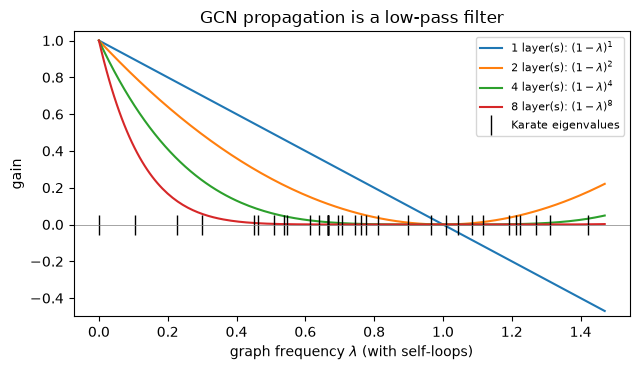

With self-loops the spectrum is in [0.00, 1.42]: self-loops keep the
largest frequency well below 2, so |1 - lambda|^k shrinks for every non-constant mode.


In [8]:
# =====================================================================
# Frequency response of k stacked (linear) GCN propagations
# =====================================================================
A_tilde = A + torch.eye(num_nodes)
d_tilde = A_tilde.sum(1)
A_hat_gcn = d_tilde.pow(-0.5)[:, None] * A_tilde * d_tilde.pow(-0.5)[None, :]
lam_sl = torch.linalg.eigvalsh(torch.eye(num_nodes) - A_hat_gcn)  # self-loop spectrum

grid = np.linspace(0, float(lam_sl.max()) + 0.05, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for k in [1, 2, 4, 8]:
    ax.plot(grid, (1 - grid) ** k, label=f"{k} layer(s): $(1-\\lambda)^{{{k}}}$")
ax.plot(lam_sl.numpy(), np.zeros(num_nodes), "k|", ms=14, label="Karate eigenvalues")
ax.axhline(0, color="gray", lw=0.5)
ax.set(
    xlabel="graph frequency $\\lambda$ (with self-loops)",
    ylabel="gain",
    title="GCN propagation is a low-pass filter",
    ylim=(-0.5, 1.05),
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(
    f"With self-loops the spectrum is in [{lam_sl.min().clamp_min(0):.2f}, {lam_sl.max():.2f}]: self-loops keep the"
)
print(
    "largest frequency well below 2, so |1 - lambda|^k shrinks for every non-constant mode."
)

<a id="6-gcn"></a>
# 6. Graph Convolutional Networks (GCN)

Adding a weight matrix $W$ and a nonlinearity $\sigma$ to the filter of Section 5.2 gives the GCN layer:

$$H^{(t+1)} = \sigma\!\left(\hat{A}\, H^{(t)} W^{(t)}\right), \qquad \hat{A} = \tilde{D}^{-1/2}(A + I)\tilde{D}^{-1/2}.$$

Node-wise, this reads $\mathbf{h}_u^{(t+1)} = \sigma\big(\sum_{v \in \mathcal{N}(u) \cup \{u\}} \frac{1}{\sqrt{\tilde{d}_u \tilde{d}_v}}\, W^\top \mathbf{h}_v^{(t)}\big)$: a **degree-weighted average** over the node and its neighbours. In MPNN terms, the message is $W^\top\mathbf{h}_v$ scaled by a fixed coefficient that depends only on degrees, the aggregator is a sum, and the update is $\sigma$.

The important point is that the coefficient $1/\sqrt{\tilde{d}_u \tilde{d}_v}$ is **fixed by the topology**. Every neighbour is trusted equally (up to degree), whatever its features say. GAT (Section 8) learns these coefficients, and sheaf models (notebook 1) replace each scalar with a learned $d \times d$ matrix.

We first check that a from-scratch dense implementation matches PyG's `GCNConv`.

In [9]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# GCN layer from scratch vs torch_geometric.nn.GCNConv
# =====================================================================
set_seed(SEED)
gcn_pyg = GCNConv(data.num_node_features, 8)

with torch.no_grad():
    out_pyg = gcn_pyg(data.x, data.edge_index)
    # PyG stores the weight in .lin (no bias) and a separate .bias.
    out_dense = A_hat_gcn @ data.x @ gcn_pyg.lin.weight.T + gcn_pyg.bias

print("--- GCN: dense formula vs PyG ---")
print(f"Max abs difference: {(out_pyg - out_dense).abs().max():.2e}")
assert torch.allclose(out_pyg, out_dense, atol=1e-5)
print("A_hat X W + b reproduces GCNConv exactly.")

--- GCN: dense formula vs PyG ---
Max abs difference: 2.98e-08
A_hat X W + b reproduces GCNConv exactly.


### 6.1 Structure Alone Already Clusters the Nodes

A striking experiment from the GCN paper: take a 3-layer GCN with **random, untrained** weights, feed it one-hot identity features, and plot the 2-D output. Because repeated neighbourhood averaging makes densely connected nodes similar, the communities separate *before any training*. The figure from the paper is shown after our reproduction for comparison.

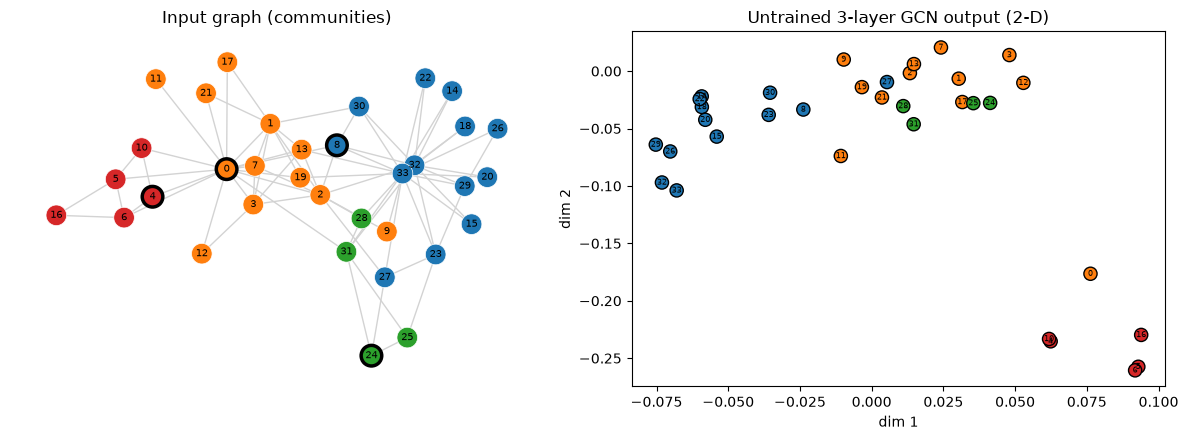

In [10]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Reproduce the random-weight GCN embedding of Kipf & Welling
# =====================================================================
set_seed(3)
random_gcn = nn.ModuleList([GCNConv(num_nodes, 16), GCNConv(16, 8), GCNConv(8, 2)])

with torch.no_grad():
    h = data.x
    for conv in random_gcn:
        h = torch.tanh(conv(h, data.edge_index))
embedding = h.numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
draw_karate(axes[0], "Input graph (communities)")
axes[1].scatter(embedding[:, 0], embedding[:, 1], c=node_colors, s=90, edgecolors="k")
for i, (a, b) in enumerate(embedding):
    axes[1].annotate(str(i), (a, b), fontsize=6, ha="center", va="center")
axes[1].set(title="Untrained 3-layer GCN output (2-D)", xlabel="dim 1", ylabel="dim 2")
plt.tight_layout()
plt.show()

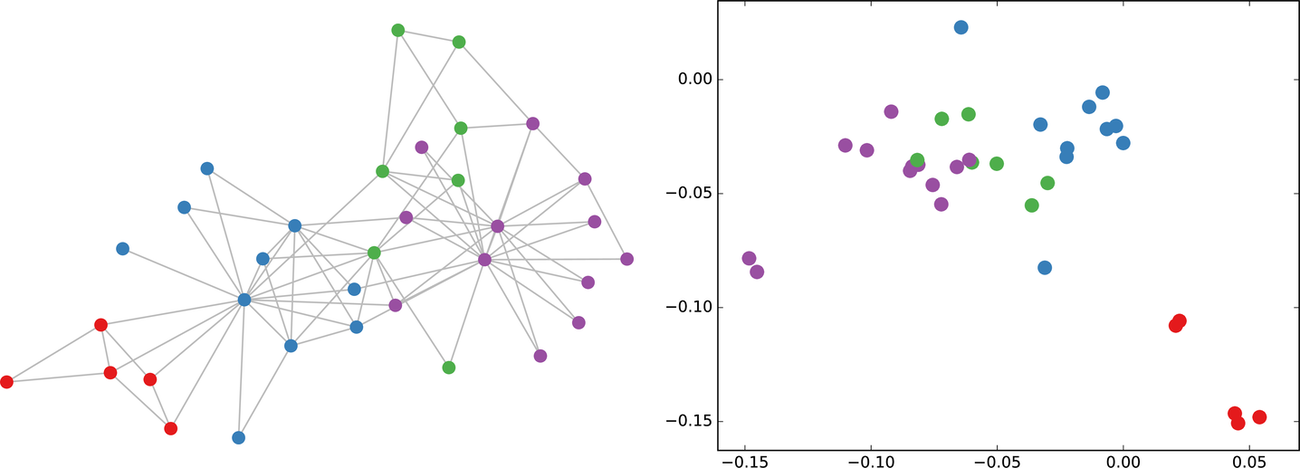

*Left: Zachary's karate club, coloured by communities from modularity-based clustering. Right: embeddings produced by an untrained 3-layer GCN with random weights. Your reproduction above differs in its exact coordinates (another random draw and layout) but shows the same effect.*

<sub>Source: Kipf & Welling (2017), *Semi-Supervised Classification with Graph Convolutional Networks*, [arXiv:1609.02907](https://arxiv.org/abs/1609.02907), Fig. 3 (appendix). Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

<a id="7-graphsage"></a>
# 7. GraphSAGE

GCN is **transductive** as originally formulated: it needs the full graph, including its degrees, at training time. **GraphSAGE** (Hamilton et al., 2017) targets **inductive** learning on large, growing graphs. It *samples* a fixed number of neighbours at each hop and learns an *aggregator* that generalizes to unseen nodes:

$$\mathbf{h}_{\mathcal{N}(u)}^{(t)} = \operatorname{AGG}\big(\{\mathbf{h}_v^{(t)} : v \in \mathcal{S}(u)\}\big), \qquad
\mathbf{h}_u^{(t+1)} = \sigma\!\left(W^{(t)}\big[\mathbf{h}_u^{(t)} \,\|\, \mathbf{h}_{\mathcal{N}(u)}^{(t)}\big]\right),$$

where $\mathcal{S}(u) \subseteq \mathcal{N}(u)$ is a uniform sample of at most $k$ neighbours, $\|$ is concatenation, and AGG is a mean, max-pooling, or LSTM aggregator. Two differences from GCN matter in practice:
* the node's own state has a **separate weight** (the concatenation), so self-information is not diluted by many neighbours;
* the cost per node is bounded by the sample sizes, independent of the true degree. This enables mini-batch training on graphs with billions of edges.

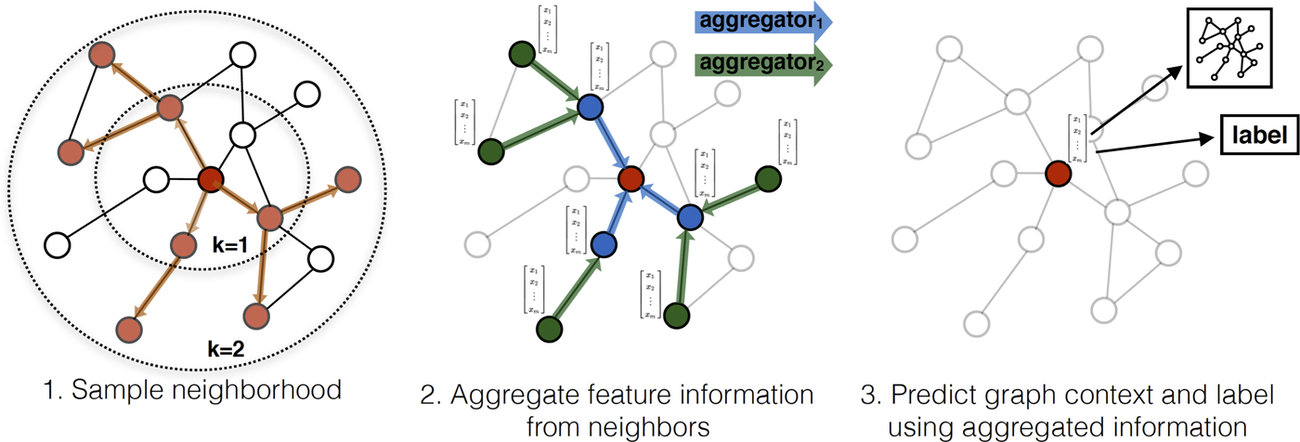

*The GraphSAGE pipeline: (1) sample a fixed-size neighbourhood at each depth, (2) aggregate the sampled features hop by hop towards the target node, and (3) use the aggregated representation for prediction.*

<sub>Source: Hamilton, Ying & Leskovec (2017), *Inductive Representation Learning on Large Graphs*, [arXiv:1706.02216](https://arxiv.org/abs/1706.02216), Fig. 1. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

Sampling makes the aggregate a **random estimate** of the full neighbourhood mean. The experiment below measures that estimation noise at the club's highest-degree node as a function of the sample size $k$. The noise shrinks roughly as $1/\sqrt{k}$, which is the accuracy/compute trade-off GraphSAGE exposes.

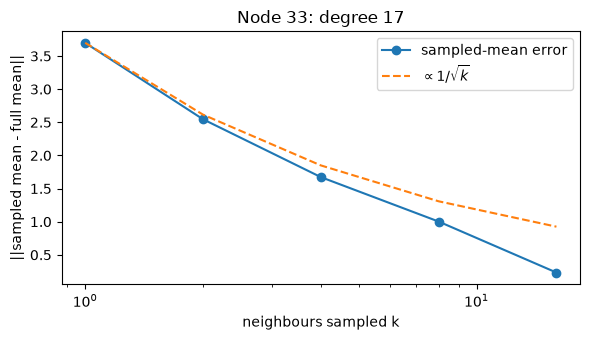

PyG SAGEConv output shape: (34, 8) (lin_r acts on the node itself, lin_l on the neighbour mean)


In [11]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Neighbour sampling: how noisy is the sampled mean aggregate?
# =====================================================================
set_seed(SEED)
node = 33
neighbours = data.edge_index[
    0, data.edge_index[1] == node
]  # sources pointing at the node
H = torch.randn(num_nodes, 16)  # a generic hidden state
full_mean = H[neighbours].mean(0)

sample_sizes = [1, 2, 4, 8, 16]
errors = []
for k in sample_sizes:
    trials = []
    for _ in range(500):
        sample = neighbours[torch.randperm(len(neighbours))[:k]]
        trials.append((H[sample].mean(0) - full_mean).norm().item())
    errors.append(np.mean(trials))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sample_sizes, errors, marker="o", label="sampled-mean error")
ax.plot(
    sample_sizes,
    errors[0] / np.sqrt(sample_sizes),
    "--",
    label="$\\propto 1/\\sqrt{k}$",
)
ax.set(
    xscale="log",
    xlabel="neighbours sampled k",
    ylabel="||sampled mean - full mean||",
    title=f"Node {node}: degree {len(neighbours)}",
)
ax.legend()
plt.tight_layout()
plt.show()

sage = SAGEConv(data.num_node_features, 8, aggr="mean")
print(
    f"PyG SAGEConv output shape: {tuple(sage(data.x, data.edge_index).shape)}"
    " (lin_r acts on the node itself, lin_l on the neighbour mean)"
)

<a id="8-gat"></a>
# 8. Graph Attention Networks (GAT)

GCN and GraphSAGE weight neighbours by fixed rules. **GAT** (Veličković et al., 2018) **learns** how much each neighbour matters with an attention mechanism:

$$e_{uv} = \operatorname{LeakyReLU}\!\left(\mathbf{a}^\top\big[W\mathbf{h}_u \,\|\, W\mathbf{h}_v\big]\right), \qquad
\alpha_{uv} = \frac{\exp(e_{uv})}{\sum_{w \in \mathcal{N}(u) \cup \{u\}} \exp(e_{uw})}, \qquad
\mathbf{h}_u' = \sigma\!\Big(\sum_{v \in \mathcal{N}(u) \cup \{u\}} \alpha_{uv}\, W\mathbf{h}_v\Big).$$

The coefficients $\alpha_{uv}$ are non-negative and sum to one over each neighbourhood, so a GAT layer is still a weighted *average*, but with data-dependent weights. **Multi-head attention** runs $K$ independent mechanisms and concatenates (hidden layers) or averages (output layer) their results, which stabilizes training.

Two remarks connect GAT to later notebooks:
* the original GAT score is *static*: the ranking of neighbours is the same for every query node. **GATv2** (Brody et al., 2022) fixes this by applying the nonlinearity before $\mathbf{a}$;
* the weights are **scalars**. They can down-weight a neighbour but never rotate or flip its features. Sheaf attention (`SHEAF_ATTN` in this repository) replaces the scalar with a learned matrix.

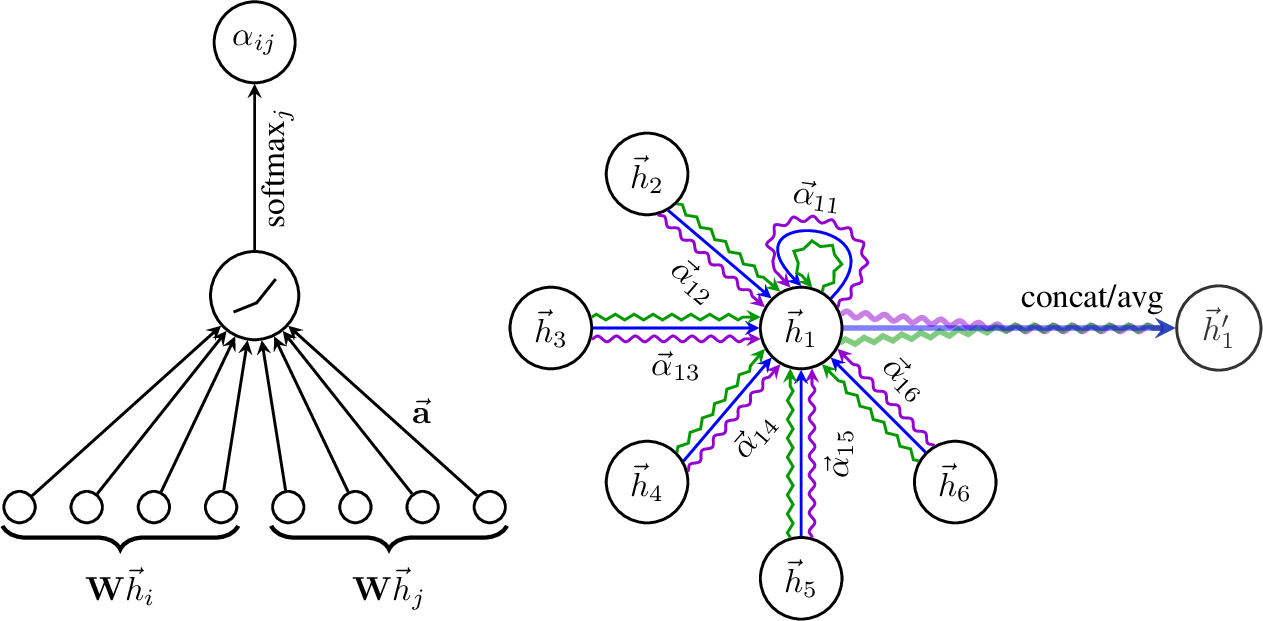

*Left: the attention mechanism a(Wh_i, Wh_j), parametrized by a weight vector and a LeakyReLU, followed by a softmax over the neighbourhood. Right: multi-head attention (K = 3 heads, different arrow styles) by node 1 on its neighbourhood; the heads are concatenated or averaged to give h'_1.*

<sub>Source: Veličković et al. (2018), *Graph Attention Networks*, [arXiv:1710.10903](https://arxiv.org/abs/1710.10903), Fig. 1. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

In [12]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Inspect GAT attention coefficients (untrained layer)
# =====================================================================
from torch_geometric.utils import scatter

set_seed(SEED)
gat = GATConv(data.num_node_features, 4, heads=2)  # concat -> 8 output channels
with torch.no_grad():
    out, (att_edge_index, alpha) = gat(
        data.x, data.edge_index, return_attention_weights=True
    )

target = att_edge_index[1]
alpha_sum = scatter(alpha, target, dim=0, dim_size=num_nodes, reduce="sum")

print("--- GAT attention ---")
print(f"Output shape: {tuple(out.shape)}  (2 heads x 4 channels, concatenated)")
print(f"Attention tensor: {tuple(alpha.shape)}  = [edges incl. self-loops, heads]")
print(
    f"Coefficients sum to 1 per target node and head: {torch.allclose(alpha_sum, torch.ones_like(alpha_sum), atol=1e-5)}"
)

# At initialization attention is close to uniform: compare entropy to log(degree).
ent = -scatter(
    alpha * alpha.clamp_min(1e-12).log(),
    target,
    dim=0,
    dim_size=num_nodes,
    reduce="sum",
)
uniform = torch.log(deg + 1)  # +1 for the self-loop
print(
    f"Mean attention entropy / uniform entropy: {(ent.mean(1) / uniform).mean():.3f}  (1.0 = perfectly uniform)"
)

--- GAT attention ---
Output shape: (34, 8)  (2 heads x 4 channels, concatenated)
Attention tensor: (190, 2)  = [edges incl. self-loops, heads]
Coefficients sum to 1 per target node and head: True
Mean attention entropy / uniform entropy: 0.995  (1.0 = perfectly uniform)


<a id="9-gin"></a>
# 9. Graph Isomorphism Networks (GIN) and Expressive Power

How many graphs can a GNN tell apart? Xu et al. (2019) connected this question to the **Weisfeiler-Lehman (1-WL) test**, a classical heuristic for graph isomorphism. 1-WL repeatedly recolours every node with a hash of its own colour and the **multiset** of its neighbours' colours. Two graphs whose colour histograms ever differ are certainly not isomorphic.

Their main results:
1. **No MPNN is more powerful than 1-WL.** If 1-WL cannot distinguish two graphs, neither can any message passing network, because message passing *is* a (soft) WL refinement.
2. An MPNN **matches** 1-WL if its aggregate-and-update step is **injective** on multisets. Sums of suitably transformed features are injective; **means** and **maxima** are not.

The resulting **Graph Isomorphism Network** uses a sum aggregator followed by an MLP:

$$\mathbf{h}_u^{(t+1)} = \operatorname{MLP}^{(t)}\!\Big((1 + \epsilon^{(t)})\,\mathbf{h}_u^{(t)} + \sum_{v \in \mathcal{N}(u)} \mathbf{h}_v^{(t)}\Big).$$

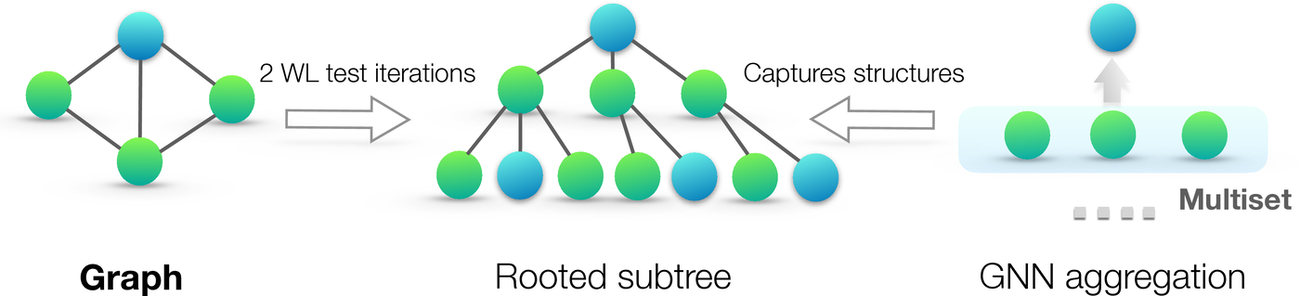

*The theoretical framework: two WL iterations capture the rooted subtree at a node. A GNN whose aggregation captures the full multiset of neighbours can encode these subtrees recursively and is therefore as powerful as the WL test.*

<sub>Source: Xu et al. (2019), *How Powerful are Graph Neural Networks?*, [arXiv:1810.00826](https://arxiv.org/abs/1810.00826), Fig. 1. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

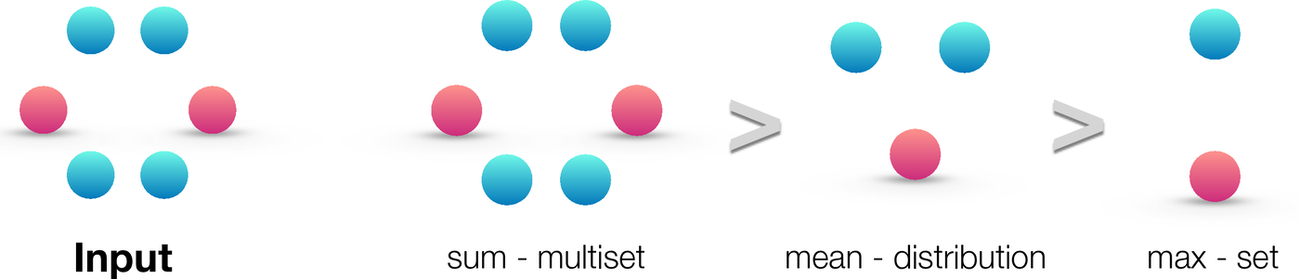

*Ranking of aggregators by expressive power over a multiset: sum captures the full multiset, mean captures only the proportion of each element type, and max ignores multiplicities and keeps only the underlying set.*

<sub>Source: Xu et al. (2019), *How Powerful are Graph Neural Networks?*, [arXiv:1810.00826](https://arxiv.org/abs/1810.00826), Fig. 2. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

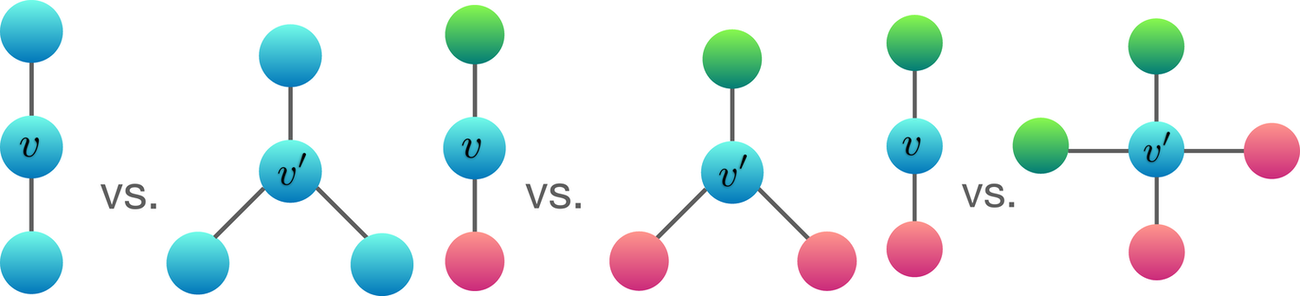

*Neighbourhoods that mean and max aggregation cannot tell apart (node colours are one-hot features): (a) mean and max both fail, (b) max fails, (c) mean and max both fail. The code below reproduces these three cases numerically.*

<sub>Source: Xu et al. (2019), *How Powerful are Graph Neural Networks?*, [arXiv:1810.00826](https://arxiv.org/abs/1810.00826), Fig. 3. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

In [13]:
# =====================================================================
# Reproduce GIN's aggregator failure cases with one-hot features
# =====================================================================
blue, green, red = torch.eye(3)  # three node "colours"

cases = {
    "(a) {b,b} vs {b,b,b}": ([blue, blue], [blue, blue, blue]),
    "(b) {g,r} vs {g,r,r}": ([green, red], [green, red, red]),
    "(c) {g,r} vs {g,g,r,r}": ([green, red], [green, green, red, red]),
}
aggregators = {
    "sum": lambda s: torch.stack(s).sum(0),
    "mean": lambda s: torch.stack(s).mean(0),
    "max": lambda s: torch.stack(s).max(0).values,
}

print(f"{'neighbourhoods':<26}" + "".join(f"{name:>14}" for name in aggregators))
for label, (left, right) in cases.items():
    verdicts = []
    for agg in aggregators.values():
        same = torch.allclose(agg(left), agg(right))
        verdicts.append("CANNOT tell" if same else "distinguishes")
    print(f"{label:<26}" + "".join(f"{v:>14}" for v in verdicts))

neighbourhoods                       sum          mean           max
(a) {b,b} vs {b,b,b}       distinguishes   CANNOT tell   CANNOT tell
(b) {g,r} vs {g,r,r}       distinguishes distinguishes   CANNOT tell
(c) {g,r} vs {g,g,r,r}     distinguishes   CANNOT tell   CANNOT tell


Even **sum** has limits, because it is bounded by 1-WL. A classic example is **two disjoint triangles** versus **one hexagon**. Both graphs have six nodes of degree two, so 1-WL assigns every node the same colour forever. Consequently *any* GIN, trained or not, maps them to the same graph embedding, although one graph contains triangles and the other does not. We check this with an explicit WL refinement and with a randomly initialized GIN followed by sum pooling.

In [14]:
# =====================================================================
# 1-WL colour refinement and a GIN on two non-isomorphic 2-regular graphs
# =====================================================================
def wl_histogram(edge_index, n, iterations=3):
    """Returns the sorted multiset of 1-WL colours after a few refinement steps."""
    colours = [0] * n
    nbrs = [[] for _ in range(n)]
    for s, t in edge_index.t().tolist():
        nbrs[t].append(s)
    for _ in range(iterations):
        signatures = [
            (colours[u], tuple(sorted(colours[v] for v in nbrs[u]))) for u in range(n)
        ]
        palette = {sig: i for i, sig in enumerate(sorted(set(signatures)))}
        colours = [palette[sig] for sig in signatures]
    return sorted(colours)


def cycle_edges(nodes):
    src = torch.tensor(nodes)
    return torch.stack([src, src.roll(-1)])


two_triangles = to_undirected(
    torch.cat([cycle_edges([0, 1, 2]), cycle_edges([3, 4, 5])], 1)
)
hexagon = to_undirected(cycle_edges([0, 1, 2, 3, 4, 5]))
star = to_undirected(
    torch.tensor([[0, 0, 0, 0, 0], [1, 2, 3, 4, 5]])
)  # a different degree profile

set_seed(SEED)
gin = nn.ModuleList(
    [
        GINConv(nn.Sequential(nn.Linear(i, 16), nn.ReLU(), nn.Linear(16, 16)))
        for i in (1, 16, 16)
    ]
)


def gin_graph_embedding(edge_index, n=6):
    h = torch.ones(n, 1)  # no node features: structure only
    with torch.no_grad():
        for i, conv in enumerate(gin):
            h = conv(torch.relu(h) if i > 0 else h, edge_index)
    return h.sum(0)  # sum pooling -> graph-level embedding


print("--- 1-WL and GIN on structurally different graphs ---")
for name, ei in [
    ("two triangles", two_triangles),
    ("hexagon", hexagon),
    ("star", star),
]:
    print(
        f"{name:<14} WL colours: {wl_histogram(ei, 6)}   GIN embedding norm: {gin_graph_embedding(ei).norm():.4f}"
    )
same = torch.allclose(gin_graph_embedding(two_triangles), gin_graph_embedding(hexagon))
print(f"\nTriangles vs hexagon indistinguishable by GIN: {same}  (both are 2-regular)")

--- 1-WL and GIN on structurally different graphs ---
two triangles  WL colours: [0, 0, 0, 0, 0, 0]   GIN embedding norm: 5.0371
hexagon        WL colours: [0, 0, 0, 0, 0, 0]   GIN embedding norm: 5.0371
star           WL colours: [0, 0, 0, 0, 0, 1]   GIN embedding norm: 5.1469

Triangles vs hexagon indistinguishable by GIN: True  (both are 2-regular)


The triangles and the hexagon receive identical WL colours and identical GIN embeddings, while the star is told apart immediately. Distinguishing the first pair requires information beyond 1-WL, such as cycle counts, positional encodings, or higher-order message passing.

<a id="10-training"></a>
# 10. Training and Comparing the Four Models

We now train two-layer versions of the four architectures on the Karate Club with the same protocol: one labelled node per class (4 nodes in total), masked cross-entropy, Adam, and evaluation on the 30 unlabelled nodes.

With so few labels and test nodes, a single run is noisy: one changed prediction moves accuracy by more than 3 points. We therefore repeat each model over several seeds and report the mean and standard deviation. These numbers illustrate the API and the inductive biases; they are not a benchmark.

In [15]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# One wrapper for the four architectures
# =====================================================================
class TwoLayerGNN(nn.Module):
    """conv -> ELU -> dropout -> conv, exposing the hidden embedding."""

    def __init__(
        self, kind: str, in_dim: int, hidden: int, out_dim: int, dropout: float = 0.2
    ):
        super().__init__()
        self.kind = kind
        if kind == "GCN":
            self.conv1, self.conv2 = GCNConv(in_dim, hidden), GCNConv(hidden, out_dim)
        elif kind == "GraphSAGE":
            self.conv1, self.conv2 = SAGEConv(in_dim, hidden), SAGEConv(hidden, out_dim)
        elif kind == "GAT":
            self.conv1 = GATConv(in_dim, hidden // 4, heads=4)  # concat heads
            self.conv2 = GATConv(hidden, out_dim, heads=1, concat=False)
        elif kind == "GIN":
            self.conv1 = GINConv(
                nn.Sequential(
                    nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden)
                )
            )
            self.conv2 = GINConv(
                nn.Sequential(
                    nn.Linear(hidden, out_dim), nn.ReLU(), nn.Linear(out_dim, out_dim)
                )
            )
        else:
            raise ValueError(kind)
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden: bool = False):
        hidden = F.elu(self.conv1(x, edge_index))
        out = self.conv2(F.dropout(hidden, self.dropout, self.training), edge_index)
        return (out, hidden) if return_hidden else out


def train_and_evaluate(kind: str, seed: int, epochs: int = 200):
    set_seed(seed)
    assert isinstance(data, Data)
    assert isinstance(data.x, torch.Tensor)
    assert isinstance(data.y, torch.Tensor)
    assert isinstance(data.edge_index, torch.Tensor)
    model = TwoLayerGNN(kind, data.num_node_features, 16, num_classes)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = F.cross_entropy(
            model(data.x, data.edge_index)[data.train_mask], data.y[data.train_mask]
        )
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(-1)
    acc = (pred[data.test_mask] == data.y[data.test_mask]).float().mean().item()
    return model, acc


KINDS = ["GCN", "GraphSAGE", "GAT", "GIN"]
SEEDS = [0, 1, 2, 3, 4]
results, trained = {}, {}
for kind in KINDS:
    accs = []
    for seed in SEEDS:
        model, acc = train_and_evaluate(kind, seed)
        accs.append(acc)
        if seed == SEEDS[0]:
            trained[kind] = model
    results[kind] = accs

print("--- Test accuracy on the 30 unlabelled nodes (5 seeds) ---")
for kind, accs in results.items():
    print(
        f"{kind:>10}: {np.mean(accs):.3f} +/- {np.std(accs):.3f}   runs: {[round(a, 3) for a in accs]}"
    )
print(
    f"\nMajority-class baseline: {(data.y[data.test_mask] == data.y[data.test_mask].mode().values).float().mean():.3f}"
)

--- Test accuracy on the 30 unlabelled nodes (5 seeds) ---
       GCN: 0.767 +/- 0.000   runs: [0.767, 0.767, 0.767, 0.767, 0.767]
 GraphSAGE: 0.520 +/- 0.054   runs: [0.533, 0.433, 0.533, 0.5, 0.6]
       GAT: 0.847 +/- 0.034   runs: [0.8, 0.867, 0.833, 0.9, 0.833]
       GIN: 0.680 +/- 0.062   runs: [0.667, 0.633, 0.667, 0.633, 0.8]

Majority-class baseline: 0.400


**Reading the table.** With identity features, a node's own input carries no class information beyond its identity, so every prediction must come from the four labels diffusing through the graph. The models whose update is a normalized *average* of the neighbourhood (GCN, and GAT, which starts from near-uniform attention) exploit the club's homophily directly and are the most stable across seeds. GraphSAGE gives the node's own one-hot input a separate weight, which lets it memorize the four training nodes instead of propagating their labels. GIN *sums* unnormalized neighbour features, so high-degree hubs dominate. Both show a much larger spread across seeds, a typical symptom of an inductive bias that matches the task less well. Rerun with more epochs or another hidden width and check how stable these conclusions are.

The hidden embeddings make the difference visible: below, each model's 16-dimensional first-layer output is projected to 2-D with PCA.

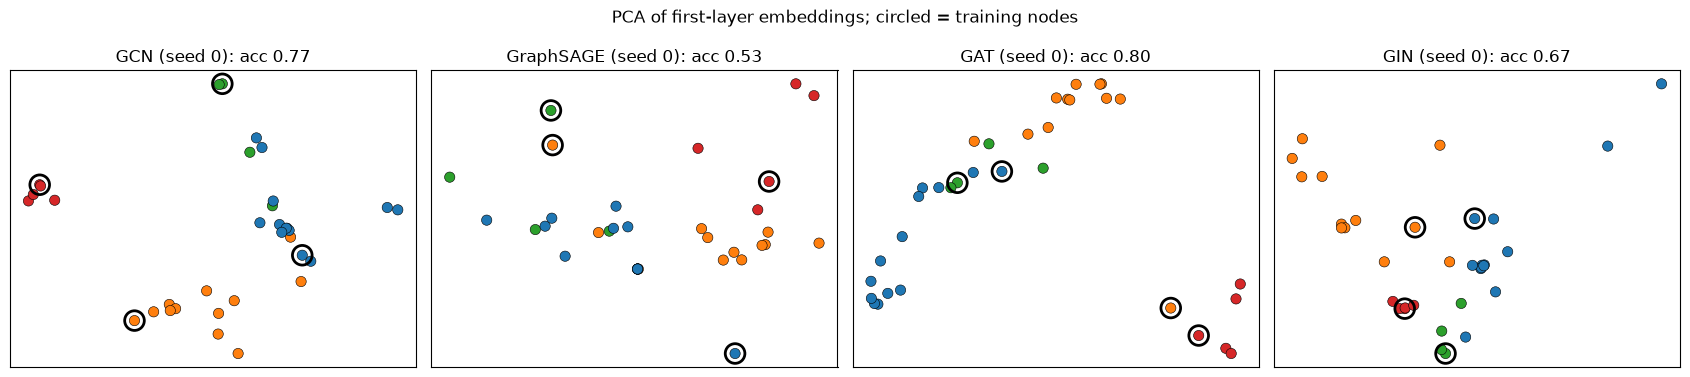

In [16]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Hidden-layer geometry of the four trained models
# =====================================================================
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, kind in zip(axes, KINDS, strict=True):
    model = trained[kind].eval()
    with torch.no_grad():
        _, hidden = model(data.x, data.edge_index, return_hidden=True)
    proj = PCA(n_components=2).fit_transform(hidden.numpy())
    ax.scatter(
        proj[:, 0], proj[:, 1], c=node_colors, s=55, edgecolors="k", linewidths=0.4
    )
    ax.scatter(
        proj[data.train_mask, 0],
        proj[data.train_mask, 1],
        s=200,
        facecolors="none",
        edgecolors="black",
        linewidths=2,
    )
    ax.set_title(f"{kind} (seed {SEEDS[0]}): acc {results[kind][0]:.2f}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("PCA of first-layer embeddings; circled = training nodes")
plt.tight_layout()
plt.show()

<a id="11-interpretability"></a>
# 11. Interpreting GNNs

Accuracy tells us *whether* a model works; interpretability asks *why*. For GNNs the natural question is: **which edges and neighbours does a prediction depend on?** We look at two complementary tools. The same questions return in every later notebook, where the object to interpret is the learned sheaf.

<a id="attention-maps"></a>
### 11.1 Attention Maps

For a trained GAT, the coefficients $\alpha_{uv}$ say how much node $u$ listened to node $v$. Below, edge width is proportional to the attention summed over both directions and averaged over heads, $\bar\alpha_{uv} + \bar\alpha_{vu}$, the same quantity the GAT authors used for their Cora visualization (shown after our plot).

Attention is a *description* of the forward pass, not a causal explanation: a large weight on a neighbour whose features are near zero can matter less than a small weight on a large one.

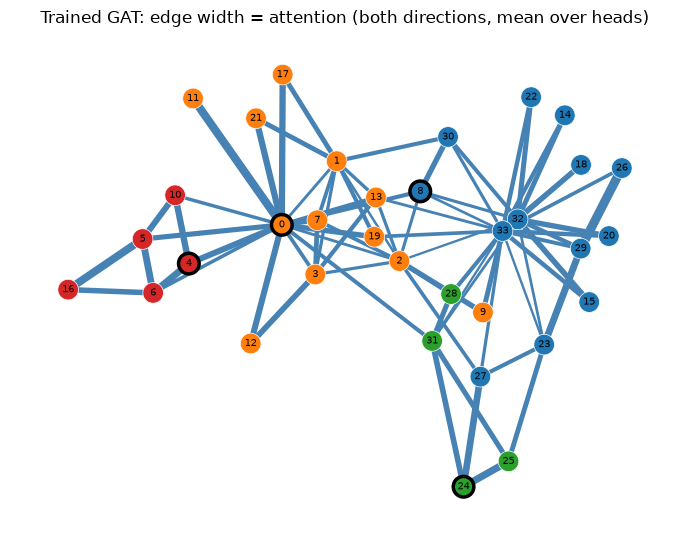

Mean attention on intra-community edges: 0.342
Mean attention on inter-community edges: 0.281


In [17]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Visualize the first-layer attention of the trained GAT
# =====================================================================
gat_model = trained["GAT"].eval()
with torch.no_grad():
    _, (ei_att, alpha) = gat_model.conv1(
        data.x, data.edge_index, return_attention_weights=True
    )

alpha_mean = alpha.mean(1)  # average over heads
weight = {}
for (s, t), a in zip(ei_att.t().tolist(), alpha_mean.tolist(), strict=True):
    if s != t:  # skip self-loops
        key = (min(s, t), max(s, t))
        weight[key] = weight.get(key, 0.0) + a

edges = list(G.edges())
widths = np.array([weight.get((min(u, v), max(u, v)), 0.0) for u, v in edges])
fig, ax = plt.subplots(figsize=(7, 5.5))
draw_karate(
    ax,
    "Trained GAT: edge width = attention (both directions, mean over heads)",
    edge_width=0.5 + 6 * widths / widths.max(),
    edge_color="steelblue",
)
plt.tight_layout()
plt.show()

same_label = np.array([int(data.y[u] == data.y[v]) for u, v in edges])
print(f"Mean attention on intra-community edges: {widths[same_label == 1].mean():.3f}")
print(f"Mean attention on inter-community edges: {widths[same_label == 0].mean():.3f}")

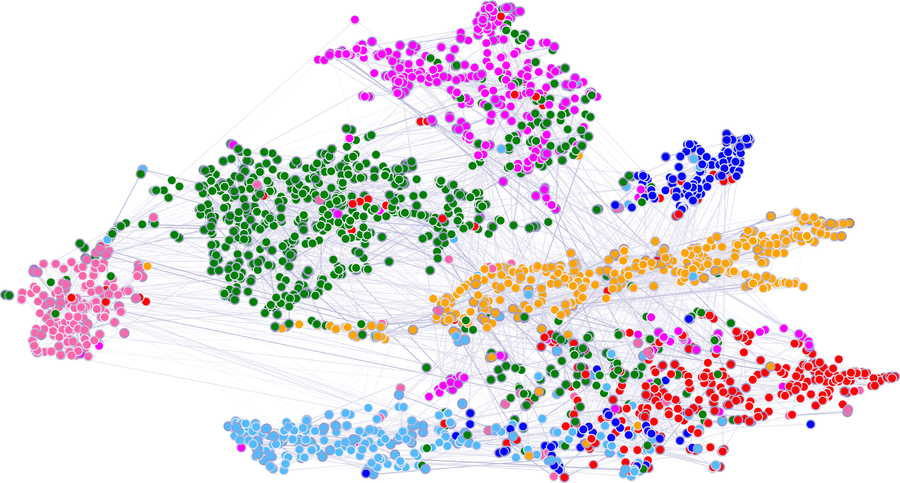

*t-SNE of a pre-trained GAT's first hidden layer on Cora. Node colours are classes; edge thickness is the aggregated normalized attention between two nodes across all eight heads.*

<sub>Source: Veličković et al. (2018), *Graph Attention Networks*, [arXiv:1710.10903](https://arxiv.org/abs/1710.10903), Fig. 2. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

<a id="edge-importance"></a>
### 11.2 Gradient-Based Edge Importance

A model-agnostic alternative asks how sensitive a prediction is to each edge. We give every edge a weight $w_e = 1$, which GCN supports natively, and compute the gradient of the target node's predicted-class logit with respect to all $w_e$. A large $|\partial z / \partial w_e|$ means that slightly strengthening or weakening edge $e$ would move the prediction.

This is a first-order *local* explanation (the basis of methods such as GNNExplainer and integrated gradients). It also exposes the receptive field: with 2 layers, edges far from the target can only act through the degree normalization, so their importance drops sharply with distance.

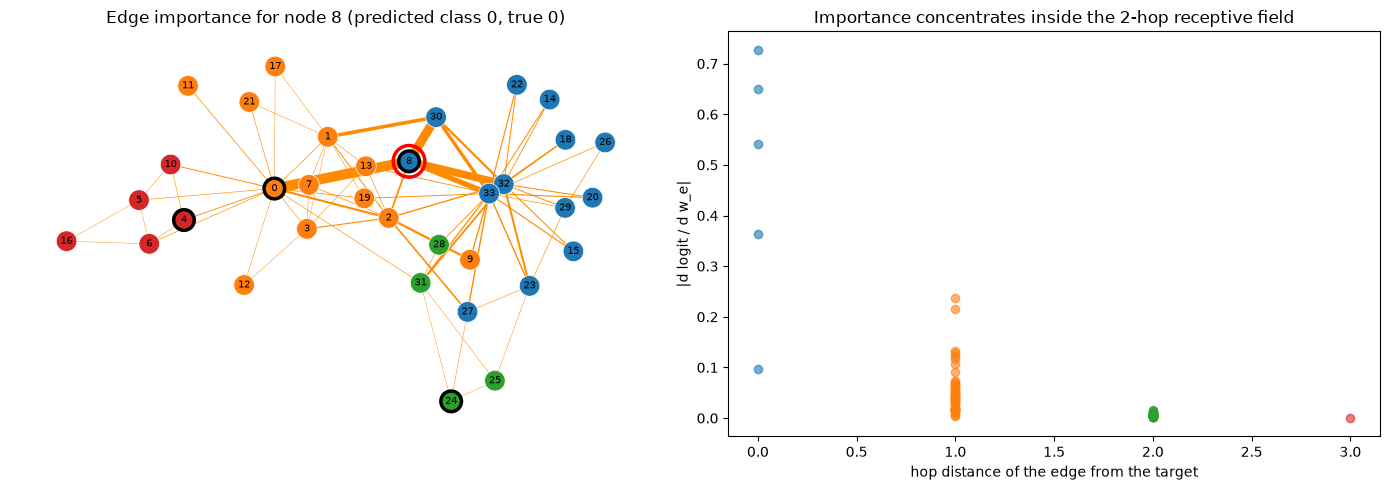

Top-5 edges: [((0, 8), 0.7275), ((8, 30), 0.6503), ((8, 32), 0.5407), ((8, 33), 0.3633), ((1, 30), 0.237)]


In [18]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Gradient of one prediction w.r.t. every edge weight (trained GCN)
# =====================================================================
gcn_model = trained["GCN"].eval()
target_node = 8  # a node on the boundary between two communities

edge_weight = torch.ones(data.num_edges, requires_grad=True)
hidden = F.elu(gcn_model.conv1(data.x, data.edge_index, edge_weight))
logits = gcn_model.conv2(hidden, data.edge_index, edge_weight)
pred_class = int(logits[target_node].argmax())
logits[target_node, pred_class].backward()
assert edge_weight.grad is not None
importance = edge_weight.grad.abs()

# Merge the two stored directions of each undirected edge.
undirected_imp = {}
for (s, t), g in zip(data.edge_index.t().tolist(), importance.tolist(), strict=True):
    key = (min(s, t), max(s, t))
    undirected_imp[key] = undirected_imp.get(key, 0.0) + g
imp = np.array([undirected_imp[(min(u, v), max(u, v))] for u, v in edges])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
draw_karate(
    axes[0],
    f"Edge importance for node {target_node} (predicted class {pred_class}, true {int(data.y[target_node])})",
    edge_width=0.3 + 7 * imp / imp.max(),
    edge_color="darkorange",
    highlight=target_node,
)

hops = nx.single_source_shortest_path_length(G, target_node)
edge_dist = np.array([min(hops[u], hops[v]) for u, v in edges])
for dist in sorted(set(edge_dist)):
    axes[1].scatter(
        np.full((edge_dist == dist).sum(), dist), imp[edge_dist == dist], alpha=0.6
    )
axes[1].set(
    xlabel="hop distance of the edge from the target",
    ylabel="|d logit / d w_e|",
    title="Importance concentrates inside the 2-hop receptive field",
)
plt.tight_layout()
plt.show()

top = np.argsort(imp)[::-1][:5]
print("Top-5 edges:", [(edges[i], round(float(imp[i]), 4)) for i in top])

<a id="12-limitations"></a>
# 12. Limitations of Classical GNNs

The same mechanisms that make GNNs work (averaging over neighbours, a fixed-size state, local aggregation) produce four well-documented failure modes. Each of them motivates part of the sheaf literature covered in the following notebooks.

<a id="oversmoothing"></a>
### 12.1 Oversmoothing

Section 5.2 showed that $\hat{A}$ multiplies frequency $\lambda$ by $(1 - \lambda)$. Applying it $k$ times damps every non-constant mode by $|1 - \lambda|^k$, so the features collapse onto the dominant eigenvector, in which node values are proportional to $\sqrt{\tilde{d}_u}$. Node representations become **indistinguishable as depth grows**, whatever the input. We track the normalized Dirichlet energy $E(H)/\|H\|^2$ over repeated propagation, for the linear operator and for a deep GCN with random weights.

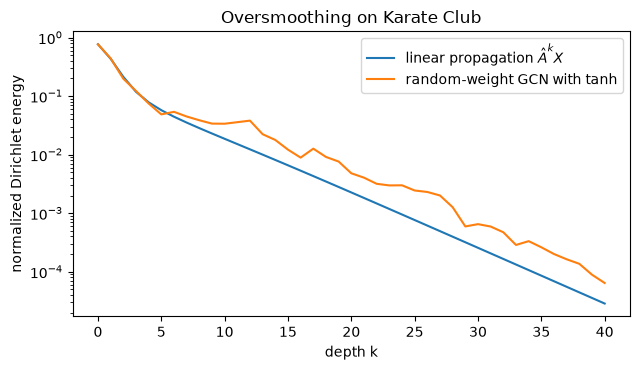

Linear propagation: energy shrinks by a factor 2.7e+04 over 40 layers.


In [19]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Dirichlet energy decays exponentially with depth
# =====================================================================
L_sym_sl = (
    torch.eye(num_nodes) - A_hat_gcn
)  # normalized Laplacian of the graph with self-loops


def normalized_energy(H):
    return (torch.trace(H.T @ L_sym_sl @ H) / (H.norm() ** 2 + 1e-12)).item()


set_seed(SEED)
H_lin = torch.randn(num_nodes, 16)
H_gcn = H_lin.clone()
depths = list(range(0, 41))
energy_linear, energy_gcn = [], []
convs = [GCNConv(16, 16) for _ in depths]
for k in depths:
    energy_linear.append(normalized_energy(H_lin))
    energy_gcn.append(normalized_energy(H_gcn))
    H_lin = A_hat_gcn @ H_lin
    with torch.no_grad():
        H_gcn = torch.tanh(convs[k](H_gcn, data.edge_index))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogy(depths, energy_linear, label="linear propagation $\\hat{A}^k X$")
ax.semilogy(depths, energy_gcn, label="random-weight GCN with tanh")
ax.set(
    xlabel="depth k",
    ylabel="normalized Dirichlet energy",
    title="Oversmoothing on Karate Club",
)
ax.legend()
plt.tight_layout()
plt.show()
print(
    f"Linear propagation: energy shrinks by a factor {energy_linear[0] / energy_linear[-1]:.1e} over {depths[-1]} layers."
)

<a id="heterophily"></a>
### 12.2 Heterophily

Averaging helps when neighbours share the label and hurts when they do not, but the relation is more subtle than "low homophily is bad". We sample 2-class **stochastic block models** with the same expected degree and an edge homophily $h$ ranging from 0 (every edge crosses classes) to 1 (no edge crosses). Every node gets a noisy 1-D feature $x_u = \pm 1 + \varepsilon$, with the sign set by its class. After two GCN propagations, we measure how separable the classes remain with the sign-invariant score $|\mu_1 - \mu_0| / \sqrt{(\sigma_0^2 + \sigma_1^2)/2}$.

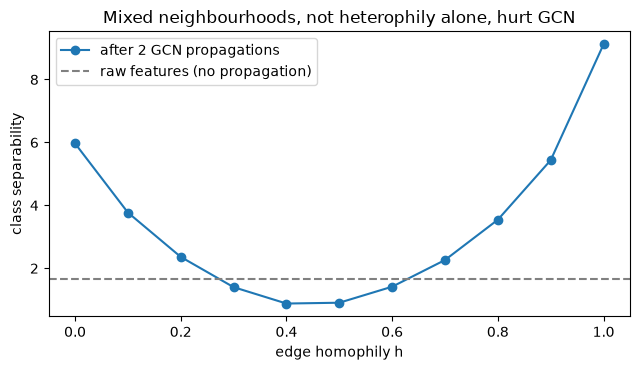

In [20]:
# =====================================================================
# Class separability after GCN propagation, as a function of homophily
# =====================================================================
def sbm_separability(h, n=400, avg_degree=10, steps=2, noise=1.5, seed=0):
    set_seed(seed)
    half = n // 2
    p_in, p_out = h * avg_degree / half, (1 - h) * avg_degree / half
    ei = stochastic_blockmodel_graph([half, half], [[p_in, p_out], [p_out, p_in]])
    y = torch.cat([torch.zeros(half), torch.ones(half)]).long()
    x = (2 * y.float() - 1 + noise * torch.randn(n))[:, None]
    Adj = to_dense_adj(ei, max_num_nodes=n)[0] + torch.eye(n)
    d = Adj.sum(1)
    P = d.pow(-0.5)[:, None] * Adj * d.pow(-0.5)[None, :]
    for _ in range(steps):
        x = P @ x
    x = x.flatten()
    m0, m1, v0, v1 = (
        x[y == 0].mean(),
        x[y == 1].mean(),
        x[y == 0].var(),
        x[y == 1].var(),
    )
    return ((m1 - m0).abs() / ((v0 + v1) / 2).sqrt()).item()


homophily_levels = np.linspace(0, 1, 11)
raw = sbm_separability(0.5, steps=0)
sep = [
    np.mean([sbm_separability(h, seed=s) for s in range(3)]) for h in homophily_levels
]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(homophily_levels, sep, marker="o", label="after 2 GCN propagations")
ax.axhline(raw, color="gray", ls="--", label="raw features (no propagation)")
ax.set(
    xlabel="edge homophily h",
    ylabel="class separability",
    title="Mixed neighbourhoods, not heterophily alone, hurt GCN",
)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** The curve is **U-shaped**. With strong homophily, averaging removes noise and separability improves well above the raw features. With *perfect* heterophily, a node's neighbours all carry the opposite sign, so each propagation flips the class signal while still averaging away noise: the classes stay separable, and a later layer can learn the flip. The damage happens in the **middle**, where each neighbourhood mixes both classes and the average cancels the signal.

A scalar-weighted average can at best down-weight a disagreeing neighbour; it cannot *transform* that neighbour's features before averaging. Sheaf diffusion adds exactly this transformation: a learned restriction map per edge can flip, rotate, or rescale a neighbour's message, so mixed neighbourhoods no longer cancel out. This is the central claim of Neural Sheaf Diffusion (notebook 1).

<a id="oversquashing"></a>
### 12.3 Oversquashing

Section 4.4 showed that the receptive field grows exponentially with depth, while each node state has a fixed size. Information from distant nodes must squeeze through **bottlenecks** (bridges between communities) and is exponentially attenuated on the way. Topping et al. (2022) bound the Jacobian $\big|\partial \mathbf{h}_u^{(r)} / \partial \mathbf{x}_v\big|$ by entries of $\hat{A}^r$, which are tiny across bottlenecks.

We build a **barbell graph**, two 6-cliques joined by a path, and compute the influence $(\hat{A}^r)_{uv}$ between opposite ends after the *minimum* number of layers $r$ needed to connect them, as the path grows.

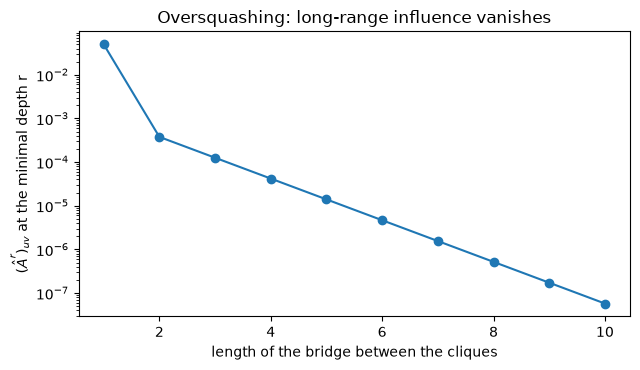

Minimal depth r for each bridge length: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


In [21]:
# =====================================================================
# Influence across a bottleneck decays exponentially with path length
# =====================================================================
def barbell_influence(path_length, clique=6):
    Gb = nx.barbell_graph(clique, path_length)
    Ab = torch.tensor(nx.to_numpy_array(Gb), dtype=torch.float) + torch.eye(
        Gb.number_of_nodes()
    )
    db = Ab.sum(1)
    P = db.pow(-0.5)[:, None] * Ab * db.pow(-0.5)[None, :]
    u, v = 0, Gb.number_of_nodes() - 1  # far ends of the two cliques
    r = nx.shortest_path_length(Gb, u, v)
    return torch.linalg.matrix_power(P, r)[u, v].item(), r


lengths = list(range(1, 11))
influence, radius = zip(*[barbell_influence(p) for p in lengths], strict=True)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogy(lengths, influence, marker="o")
ax.set(
    xlabel="length of the bridge between the cliques",
    ylabel="$(\\hat{A}^r)_{uv}$ at the minimal depth r",
    title="Oversquashing: long-range influence vanishes",
)
plt.tight_layout()
plt.show()
print("Minimal depth r for each bridge length:", list(radius))

Remedies include rewiring the graph, adding virtual or global nodes, and propagating with operators that are not purely local. In this series, **Bundle Neural Networks** (notebook 6) replace message *passing* with message *diffusion* through a heat kernel, and **Polynomial NSD** (notebook 4) reaches $K$ hops in one layer.

**Expressivity** (Section 9) is the fourth limitation: no MPNN, sheaf-based or not, exceeds 1-WL with plain node features. Sheaves change *how* information is compared and transported, not the WL bound. Keep this distinction in mind when reading results.

<a id="gnns-to-sheaves"></a>
### 12.4 From GNNs to Sheaves

A **cellular sheaf** attaches a vector space to every node and edge, plus a linear **restriction map** $\mathcal{F}_{u \trianglelefteq e}$ for every node-edge incidence. Its **sheaf Laplacian** compares neighbours *after* mapping them into the edge space:

$$(L_\mathcal{F}\mathbf{x})_u = \sum_{e = (u,v)} \mathcal{F}_{u \trianglelefteq e}^\top\big(\mathcal{F}_{u \trianglelefteq e}\mathbf{x}_u - \mathcal{F}_{v \trianglelefteq e}\mathbf{x}_v\big).$$

With every map equal to the identity, $L_\mathcal{F} = L$: classical GNN diffusion is the **trivial sheaf**. The smallest non-trivial example already resolves the heterophily problem of Section 12.2. Take a ring whose labels alternate, with the signal $x_u = (-1)^u$, and set $\mathcal{F}_{u \trianglelefteq e} = 1$, $\mathcal{F}_{v \trianglelefteq e} = -1$ on every edge, which "agrees" when neighbours have *opposite* signs.
* Graph heat diffusion $\dot{\mathbf{x}} = -L\mathbf{x}$ destroys the alternating signal, the graph's highest frequency.
* Sheaf heat diffusion $\dot{\mathbf{x}} = -L_\mathcal{F}\mathbf{x}$ leaves it untouched, because the alternating signal now has **zero** sheaf Dirichlet energy: it is a *global section* of the sheaf.

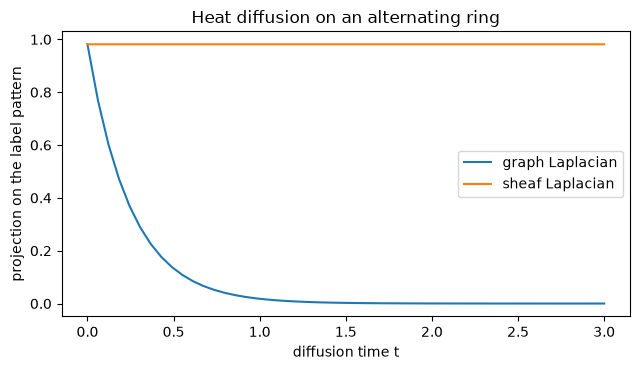

Graph Dirichlet energy of the alternating signal: 48.0
Sheaf Dirichlet energy of the alternating signal: 0.0  (a global section)


In [22]:
# =====================================================================
# Graph diffusion vs sheaf diffusion on an alternating ring
# =====================================================================
n_ring = 12
x_alt = torch.tensor([(-1.0) ** u for u in range(n_ring)]) + 0.3 * torch.randn(n_ring)
ring = [(u, (u + 1) % n_ring) for u in range(n_ring)]

L_graph = torch.zeros(n_ring, n_ring)
L_sheaf = torch.zeros(n_ring, n_ring)
for u, v in ring:
    # Graph Laplacian: identity restriction maps.
    L_graph[[u, v], [u, v]] += 1
    L_graph[u, v] -= 1
    L_graph[v, u] -= 1
    # Sheaf Laplacian with F_u = 1, F_v = -1:  F_u^T F_v = -1, so off-diagonals become +1.
    L_sheaf[[u, v], [u, v]] += 1
    L_sheaf[u, v] += 1
    L_sheaf[v, u] += 1

alternating = torch.tensor([(-1.0) ** u for u in range(n_ring)])
times = np.linspace(0, 3, 50)
stats = {"graph Laplacian": [], "sheaf Laplacian": []}
for t in times:
    for name, Lap in [("graph Laplacian", L_graph), ("sheaf Laplacian", L_sheaf)]:
        x_t = torch.matrix_exp(-t * Lap) @ x_alt
        # Strength of the label pattern: projection onto the alternating signal.
        stats[name].append((x_t @ alternating / n_ring).item())

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, values in stats.items():
    ax.plot(times, values, label=name)
ax.set(
    xlabel="diffusion time t",
    ylabel="projection on the label pattern",
    title="Heat diffusion on an alternating ring",
)
ax.legend()
plt.tight_layout()
plt.show()

print(
    f"Graph Dirichlet energy of the alternating signal: {alternating @ L_graph @ alternating:.1f}"
)
print(
    f"Sheaf Dirichlet energy of the alternating signal: {alternating @ L_sheaf @ alternating:.1f}  (a global section)"
)

The graph diffusion erases the label signal, while the sheaf diffusion preserves it, because the restriction maps encode the *relationship* between neighbours. Neural Sheaf Diffusion **learns** these maps from data, per edge and in $d$ dimensions, instead of fixing them by hand. Notebook 1 develops this idea in full.

<a id="13-summary"></a>
# 13. Summary and Exercises

| Model | Neighbour weighting | Aggregator | Key idea | Main limitation |
|---|---|---|---|---|
| **GCN** | fixed, $1/\sqrt{\tilde{d}_u\tilde{d}_v}$ | weighted sum | first-order spectral filter (low-pass) | oversmoothing, heterophily |
| **GraphSAGE** | uniform over a sample | mean / max / LSTM | inductive, scalable sampling | sampling noise, still averages |
| **GAT** | learned scalar $\alpha_{uv}$ | weighted sum | data-dependent attention | static attention, scalar only |
| **GIN** | none (sum) | sum + MLP | injective, as powerful as 1-WL | bounded by 1-WL, degree-sensitive |
| **Sheaf (NSD)** | learned $d\times d$ maps $\mathcal{F}_{u \trianglelefteq e}$ | transported difference | per-edge geometry | cost of learning maps |

**Key takeaways**
* Every model here is a message passing network; they differ in how messages are weighted and aggregated.
* GCN-style averaging is a low-pass filter: excellent under homophily, harmful with mixed neighbourhoods, and prone to oversmoothing with depth.
* Interpretability tools such as attention maps and gradients reveal which edges a prediction uses, but they are descriptive and local.
* Sheaves generalize the graph Laplacian. Identity maps recover classical diffusion; learned maps let neighbours relate through transformations rather than plain similarity.

### Hands-on Exercises
1. **Depth.** Train the four models with 4 and 8 layers (extend `TwoLayerGNN`). Which degrades first, and does the Dirichlet energy of the hidden states explain it?
2. **Features.** Replace the identity features with constant ones. Which architecture can still learn, and why does GIN behave differently from GCN?
3. **Heterophily.** Train GCN and an MLP on SBM graphs at $h = 0.0$, $0.5$, $1.0$ (Section 12.2). Does the trained GCN follow the U-shape of the propagation analysis?
4. **Attention.** Compare the attention map with the gradient-based importance for the same node. When do they disagree?
5. **Sheaves.** In Section 12.4, set the restriction map of a single edge back to $+1$. What happens to the global section, and why? (Hint: compute the sheaf Dirichlet energy of the alternating signal.)

Continue with **notebook 1**, where the restriction maps become learnable neural networks.